# Linear Regression Lab (SciKit-Learn) — Salary Dataset
## Student Notebook (Fill in the Blanks)

This notebook is available in the codebase that comes along with the book. In this exercise, you will learn how to implement Linear Regression using Scikit-learn, how to build a Machine Learning regression model, and how to draw relevant plots.

**Dataset:** Salary dataset from the codebase (example: `Salary_Data.csv`).

Follow the step-by-step instructions and complete each cell.

## Step 1 — Import Required Libraries
**Task:** Complete the imports.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 2 — Load the Salary Dataset
**Task:** Read the CSV file from the codebase and display top rows.

In [2]:
df = pd.read_csv("Salary_Data.csv")   # e.g., "Salary_Data.csv"
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


## Step 3 — Explore the Dataset
**Task:** Print shape, columns, missing values, and statistics.

In [3]:
print("Shape:", df.shape)

print("\nColumns:", df.columns.tolist())

print("\nMissing values:\n", df.isnull().sum())

df.describe()

Shape: (30, 2)

Columns: ['YearsExperience', 'Salary']

Missing values:
 YearsExperience    0
Salary             0
dtype: int64


,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


## Step 4 — Define Features (X) and Target (y)
**Task:** Use `YearsExperience` as X and `Salary` as y. Remember: X must be 2D.

In [4]:
X = df[[ "YearsExperience" ]]     # YearsExperience
y = df["Salary"]           # Salary

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30, 1)
y shape: (30,)


## Step 5 — Split Dataset into Training and Test Sets
**Task:** Use `train_test_split` with a test size and random state.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (24, 1) X_test: (6, 1)


## Step 6 — Train the Linear Regression Model
**Task:** Create and fit the model. Print intercept and coefficient.

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 26561.506762425277
Coefficient: 9339.90339715483


## Step 7 — Make Predictions
**Task:** Predict salary for the test set and display first 5 rows of results.

In [7]:
y_pred = model.predict(X_test)

pd.DataFrame({
    "YearsExperience": X_test["YearsExperience"].values,
    "ActualSalary": y_test.values,
    "PredictedSalary": y_pred
}).head()

,YearsExperience,ActualSalary,PredictedSalary
0,6.0,93940.0,82600.927145
1,4.0,55794.0,63921.120351
2,1.5,37731.0,40571.361858
3,3.7,57189.0,61119.149332
4,8.7,109431.0,107818.666318


## Step 8 — Evaluate the Model
**Task:** Compute MAE, MSE, RMSE, and R².

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 5239.769575530893
MSE : 38937181.275503
RMSE: 6239.966448267411
R^2 : 0.9531732818427658


# Visualization Section

## Step 9 — Scatter Plot of Actual Data
**Task:** Create a scatter plot of YearsExperience vs Salary.

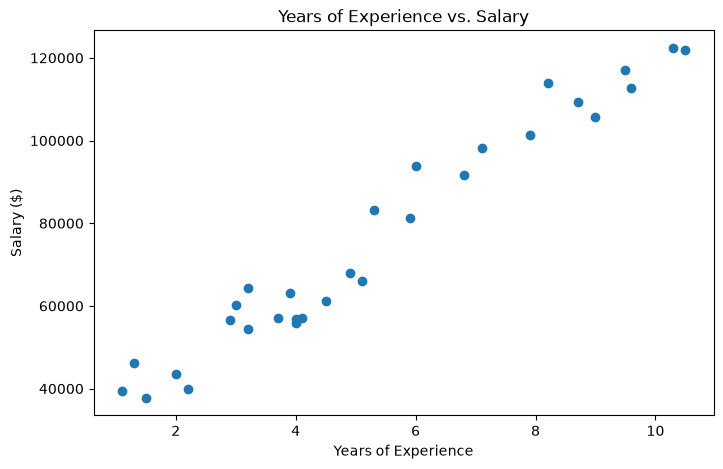

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["YearsExperience"], df["Salary"])
plt.title("Years of Experience vs. Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.show()

## Step 10 — Plot Regression Line (Train Set)
**Task:** Plot training points and regression line.

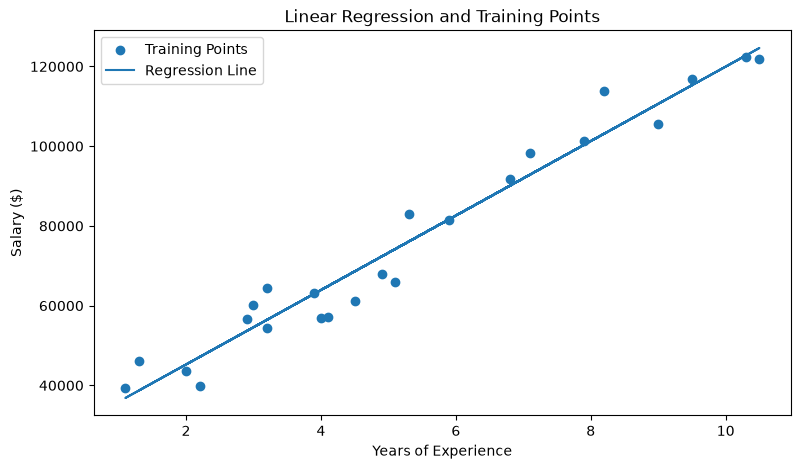

In [10]:
plt.figure(figsize=(9, 5))
plt.scatter(X_train["YearsExperience"], y_train, label="Training Points")

y_train_line = model.predict(X_train)
plt.plot(X_train["YearsExperience"], y_train_line, label="Regression Line")

plt.title("Linear Regression and Training Points")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.legend()
plt.show()

## Step 11 — Plot Regression Line (Test Set)
**Task:** Plot test points and regression line (sorted X for a clean line).

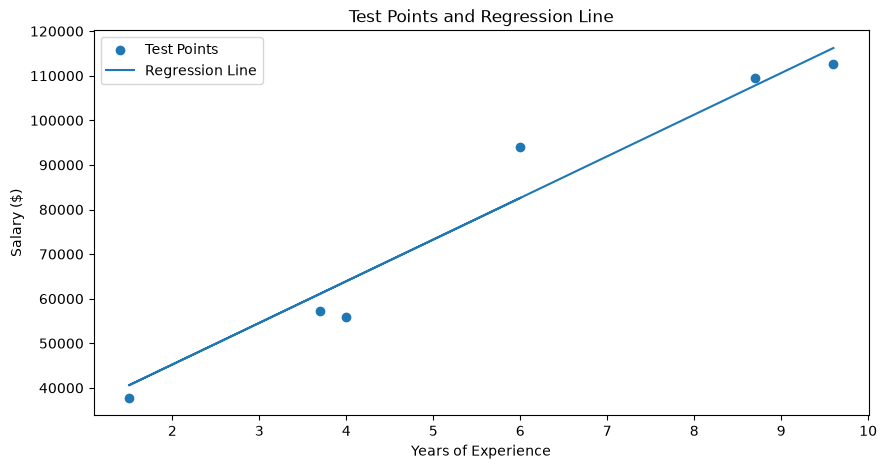

In [11]:
plt.figure(figsize=(10, 5))

plt.scatter(X_test["YearsExperience"], y_test, label="Test Points")

y_test_line = model.predict(X_test)
plt.plot(X_test["YearsExperience"], y_test_line, label="Regression Line")

plt.title("Test Points and Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary ($)")
plt.legend()
plt.show()

## Step 12 — Residual Plot (Optional)
**Task:** Compute residuals and plot residuals vs predicted values.

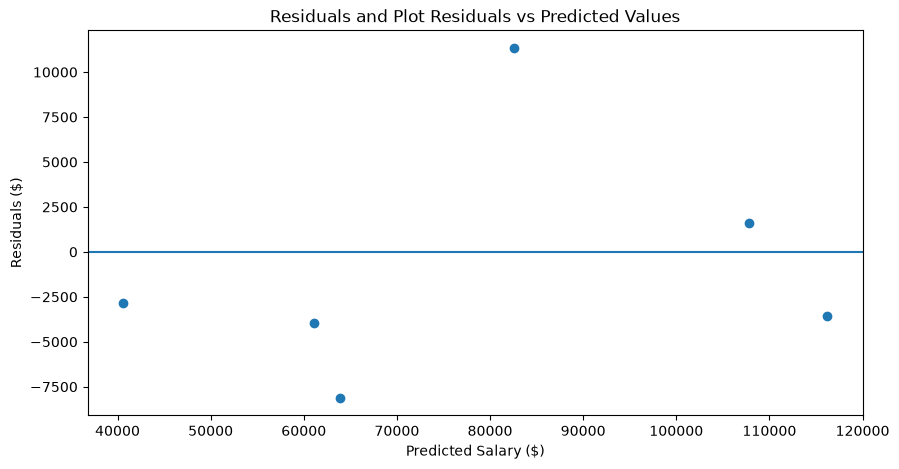

In [12]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
plt.scatter(y_pred, residuals)
plt.axhline(0)
plt.title("Residuals and Plot Residuals vs Predicted Values")
plt.xlabel("Predicted Salary ($)")
plt.ylabel("Residuals ($)")
plt.show()

# Mini Exercises (Write Your Answers)
**Exercise A:** What does the slope represent in this dataset?

**Exercise B:** If the model has a high R², what does it indicate?

**Exercise C:** How can outliers affect the regression line?


In [13]:
# Exercise A:
# In this dataset, the slope represents the estimated increase in salary for each additionial year of work experience.
# For example, our model above (the coefficient which was calculated in step 6) calculated that the slope was 9339.90339715483.
# This tells us that every year of additional experience would add approximately 9340$ to the annual salary.

# Exercise B:
# When the model has a high R^2 it indicates that our linear regression model is a reliable predictor of salary based on years of experience.
# However, a distinction must be made clear. A high R^2 doesn't mean that the prediction will be 100% accurate. After all, it is just a prediction.
# Instead, it does indicate that our linear regression model is reliable and that it does have the capability to predict salary.

# Exercise C:
# Outliers can affect the regression line by pulling the regression line towards unusually high or low values.
# In fact, an outlier has the capability to greatly influence the slope and intercept points on a graph.
# This results in the model being overall less accurate at being a predictor for salories. 

# Extension Challenge (Optional)
1. Change the test size (example: 0.2 → 0.3)
2. Retrain the model and compare evaluation metrics
3. Write your conclusion in 2–3 lines


In [14]:
# YOUR CODE HERE